# Philippine Peso Bill Identifier

This notebook follows the image breakdown style of `activity02.ipynb`. It detects visible peso-bill regions, estimates each denomination from its color family, and places the estimated value above each detected bill.

Because the supplied image contains overlapping bills, this is a color-and-region estimate. A clear photograph with separated bills gives more reliable results.

## 1. Import the image-processing libraries

NumPy stores pixel arrays, OpenCV performs color conversion and contours, Matplotlib displays processing stages, and scikit-image labels connected regions.

In [37]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

## 2. Load and display the peso-bill image

OpenCV reads the image as BGR, so it is converted to RGB before displaying it.

Image size: 4032 x 3024 pixels


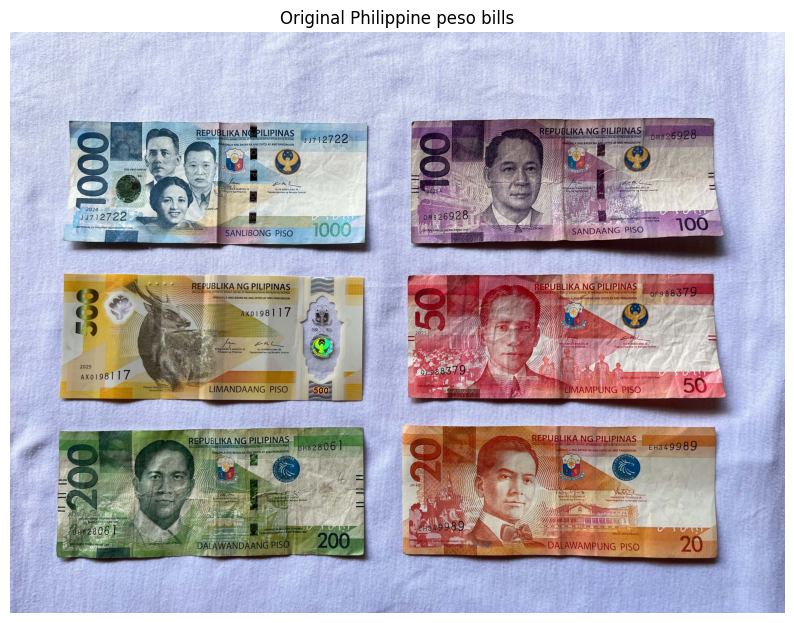

In [38]:
IMAGE_PATH = Path('Assets/Peso-Bill.jpg')
image_bgr = cv2.imread(str(IMAGE_PATH))
if image_bgr is None:
    raise FileNotFoundError(f'Could not load image: {IMAGE_PATH}')

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
height, width = image_rgb.shape[:2]
print(f'Image size: {width} x {height} pixels')

plt.figure(figsize=(10, 8))
plt.imshow(image_rgb)
plt.title('Original Philippine peso bills')
plt.axis('off')
plt.show()

## 3. Break the image into color channels

The RGB channels reveal the color differences between denominations. HSV is then used because hue and saturation are easier to compare than raw RGB values.

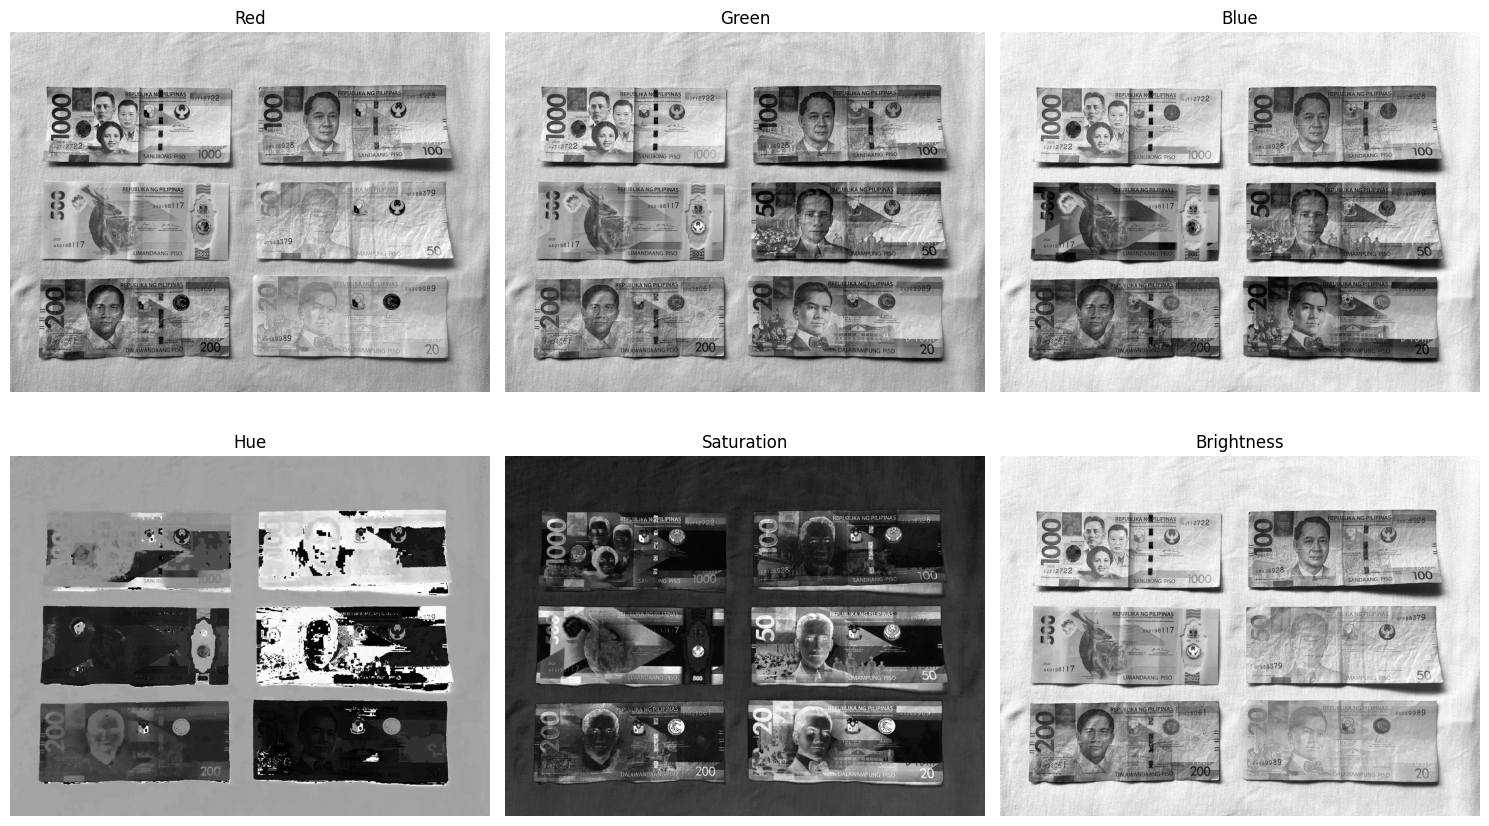

In [39]:
red, green, blue = cv2.split(image_rgb)
gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
hsv = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV)
hue, saturation, brightness = cv2.split(hsv)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
channels = [red, green, blue, hue, saturation, brightness]
titles = ['Red', 'Green', 'Blue', 'Hue', 'Saturation', 'Brightness']
for axis, channel, title in zip(axes.ravel(), channels, titles):
    axis.imshow(channel, cmap='gray')
    axis.set_title(title)
    axis.axis('off')
plt.tight_layout()
plt.show()

## 4. Create a bill foreground mask

This exploratory mask highlights colorful pixels for channel comparison. It is not used to locate bills because a hue-only mask breaks each note into separate patches.

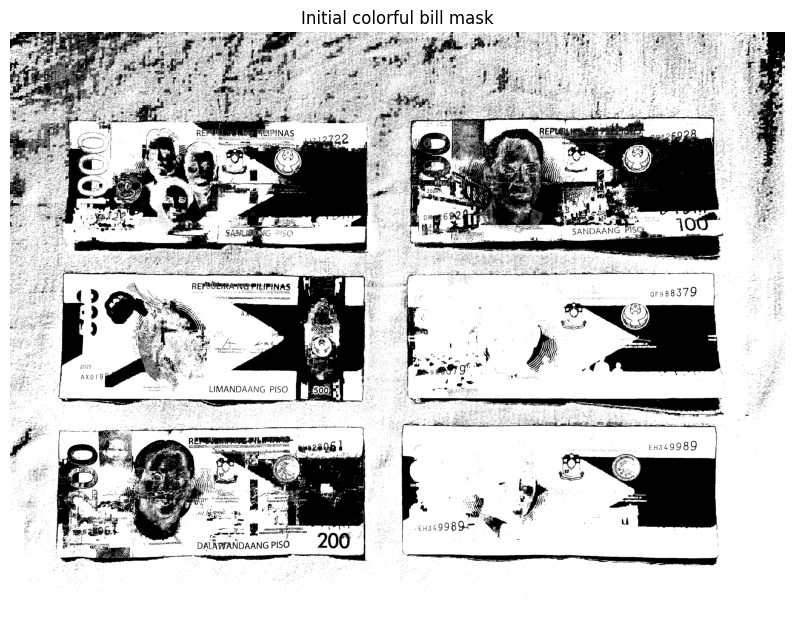

In [40]:
foreground_mask = cv2.inRange(
    hsv,
    np.array([0, 35, 70], dtype=np.uint8),
    np.array([179, 255, 255], dtype=np.uint8),
)

plt.figure(figsize=(10, 8))
plt.imshow(foreground_mask, cmap='gray')
plt.title('Initial colorful bill mask')
plt.axis('off')
plt.show()

## 5. Clean the mask with morphology

Opening removes small noise, while closing connects nearby pixels. The bill detector in step 6 uses a brightness-based shape mask instead.

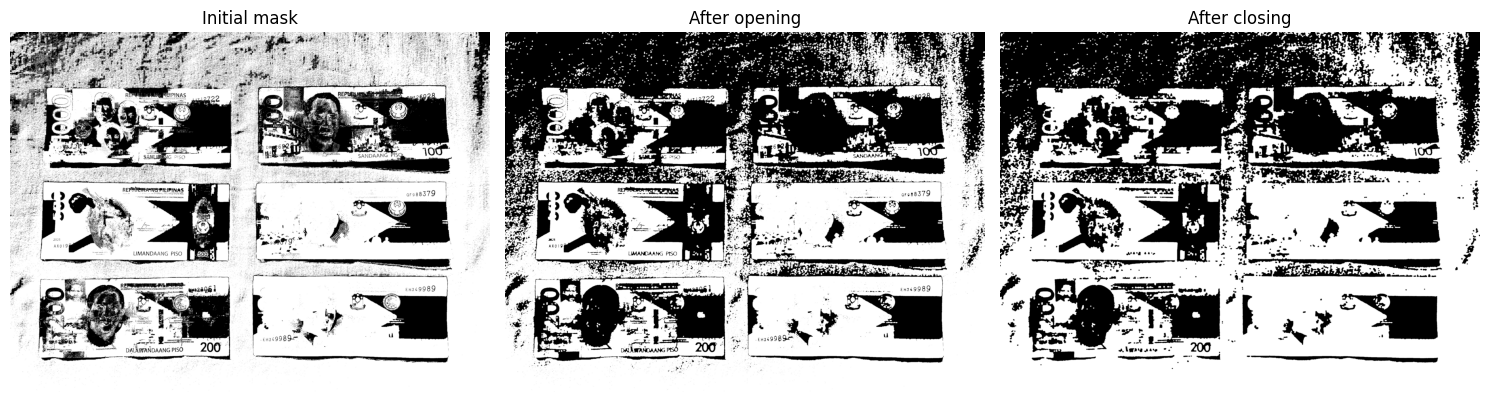

In [41]:
morphology_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
opened_mask = cv2.morphologyEx(foreground_mask, cv2.MORPH_OPEN, morphology_kernel)
clean_bill_mask = cv2.morphologyEx(opened_mask, cv2.MORPH_CLOSE, morphology_kernel)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for axis, mask, title in zip(
    axes, [foreground_mask, opened_mask, clean_bill_mask],
    ['Initial mask', 'After opening', 'After closing'],
):
    axis.imshow(mask, cmap='gray')
    axis.set_title(title)
    axis.axis('off')
plt.tight_layout()
plt.show()

## 6. Locate visible bill regions

A brightness-based Otsu threshold separates the darker notes from the light fabric. Morphological closing joins printed details, then bill-sized contours are filtered by area and banknote aspect ratio.

In [42]:
# Detect complete bill-shaped regions from brightness, not isolated hue patches.
blurred_brightness = cv2.GaussianBlur(hsv[:, :, 2], (5, 5), 0)
otsu_threshold, bill_mask = cv2.threshold(
    blurred_brightness, 0, 255, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU
)
closing_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (31, 31))
bill_mask = cv2.morphologyEx(bill_mask, cv2.MORPH_CLOSE, closing_kernel)
contours, _ = cv2.findContours(bill_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

min_bill_area = image_rgb.shape[0] * image_rgb.shape[1] * 0.02
bill_regions = []
for contour in contours:
    area = cv2.contourArea(contour)
    x, y, box_width, box_height = cv2.boundingRect(contour)
    aspect_ratio = box_width / box_height
    if (
        area < min_bill_area
        or box_width < width * 0.2
        or box_height < height * 0.12
        or not 1.8 <= aspect_ratio <= 2.8
    ):
        continue

    contour_offset = contour - np.array([x, y], dtype=np.int32)
    region_mask = np.zeros((box_height, box_width), dtype=np.uint8)
    cv2.drawContours(region_mask, [contour_offset], -1, 255, -1)
    moments = cv2.moments(contour)
    center_x = moments['m10'] / moments['m00'] if moments['m00'] else x + box_width / 2
    center_y = moments['m01'] / moments['m00'] if moments['m00'] else y + box_height / 2

    bill_regions.append({
        'mask': region_mask,
        'contour': contour,
        'area': area,
        'bbox': (y, x, y + box_height, x + box_width),
        'centroid': (center_y, center_x),
    })

row_height = np.median([region['bbox'][2] - region['bbox'][0] for region in bill_regions]) * 1.25
bill_regions.sort(key=lambda region: (int(region['centroid'][0] / row_height), region['bbox'][1]))
print(f'Bill-shaped regions detected: {len(bill_regions)}')
for index, region in enumerate(bill_regions, start=1):
    print(f"Region {index}: area={region['area']:.0f} pixels, bbox={region['bbox']}")


Bill-shaped regions detected: 6
Region 1: area=710540 pixels, bbox=(466, 307, 1157, 1886)
Region 2: area=1118872 pixels, bbox=(451, 2086, 1205, 3761)
Region 3: area=762932 pixels, bbox=(1269, 268, 1954, 1858)
Region 4: area=1091830 pixels, bbox=(1261, 2066, 2012, 3753)
Region 5: area=1083638 pixels, bbox=(2047, 241, 2767, 1875)
Region 6: area=1106718 pixels, bbox=(2052, 2044, 2795, 3712)


## 7. Estimate denomination from bill color

Each detected region is classified by the most common hue among its saturated pixels. These color-family ranges fit this photo and may need recalibration under different lighting.

In [43]:
DENOMINATION_HUE_RANGES = {
    '50 pesos': ((0, 9), (170, 180)),
    '20 pesos': ((9, 20),),
    '500 pesos': ((20, 40),),
    '200 pesos': ((40, 90),),
    '1000 pesos': ((90, 130),),
    '100 pesos': ((130, 170),),
}

bill_measurements = []
for index, region in enumerate(bill_regions, start=1):
    min_row, min_col, max_row, max_col = region['bbox']
    inset_y = int((max_row - min_row) * 0.1)
    inset_x = int((max_col - min_col) * 0.1)
    local_hsv = hsv[min_row + inset_y:max_row - inset_y, min_col + inset_x:max_col - inset_x]
    valid_pixels = local_hsv[(local_hsv[:, :, 1] >= 45) & (local_hsv[:, :, 2] >= 40)]
    if not valid_pixels.size:
        raise ValueError(f'No saturated pixels available to classify bill region {index}.')
    hue_counts = np.bincount(valid_pixels[:, 0], minlength=180)
    denomination_scores = {
        denomination: sum(int(hue_counts[start:end].sum()) for start, end in ranges)
        for denomination, ranges in DENOMINATION_HUE_RANGES.items()
    }
    denomination = max(denomination_scores, key=denomination_scores.get)
    mean_hsv = local_hsv.mean(axis=(0, 1)).astype(np.float32)
    bill_measurements.append({
        'id': index,
        'denomination': denomination,
        'area': region['area'],
        'centroid': region['centroid'],
        'bbox': region['bbox'],
        'mask': region['mask'],
        'contour': region['contour'],
        'mean_hsv': mean_hsv,
    })
    print(f"Bill {index}: estimated value={denomination}, mean HSV={mean_hsv.round(1)}")


Bill 1: estimated value=1000 pesos, mean HSV=[ 81.9  56.7 176.1]
Bill 2: estimated value=100 pesos, mean HSV=[126.2  59.6 141.1]
Bill 3: estimated value=500 pesos, mean HSV=[ 33.2  79.5 152.1]
Bill 4: estimated value=50 pesos, mean HSV=[ 85.  104.8 177.2]
Bill 5: estimated value=200 pesos, mean HSV=[ 48.4  71.9 128.4]
Bill 6: estimated value=20 pesos, mean HSV=[ 18.3 114.8 172. ]


## 8. Place the estimated value above each bill

The detected bill contour is drawn in color, and the estimated denomination is placed above its bounding box. Shape-based detection works best when bills are separated from one another.

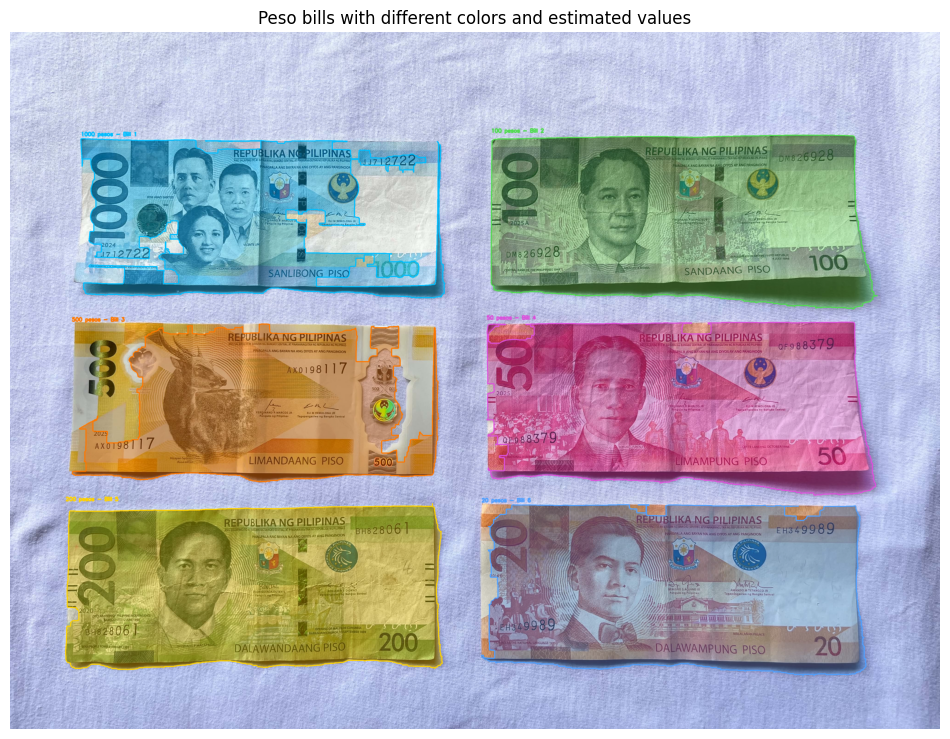

In [44]:
annotated_image = image_rgb.copy()
fill_colors = [
    (0, 190, 255),
    (80, 220, 80),
    (255, 120, 0),
    (220, 80, 220),
    (255, 210, 0),
    (80, 160, 255),
]

for bill in bill_measurements:
    min_row, min_col, max_row, max_col = bill['bbox']
    color = fill_colors[(bill['id'] - 1) % len(fill_colors)]
    overlay = annotated_image.copy()
    roi = overlay[min_row:max_row, min_col:max_col]
    roi[bill['mask'] > 0] = color
    overlay[min_row:max_row, min_col:max_col] = roi
    annotated_image = cv2.addWeighted(overlay, 0.35, annotated_image, 0.65, 0)
    cv2.drawContours(annotated_image, [bill['contour']], -1, color, 4)

    label_text = f"{bill['denomination']} - Bill {bill['id']}"
    label_x = max(min_col, 5)
    label_y = max(min_row - 12, 30)
    cv2.putText(
        annotated_image, label_text, (label_x, label_y),
        cv2.FONT_HERSHEY_SIMPLEX, 0.75, color, 3, cv2.LINE_AA,
    )

plt.figure(figsize=(12, 10))
plt.imshow(annotated_image)
plt.title('Peso bills with different colors and estimated values')
plt.axis('off')
plt.show()


## 9. Detection summary

This summary reports the number of bill regions and the estimated value assigned to each region.

In [45]:
print(f'Total detected bill regions: {len(bill_measurements)}')
for bill in bill_measurements:
    print(f"Region {bill['id']}: {bill['denomination']}")

Total detected bill regions: 6
Region 1: 1000 pesos
Region 2: 100 pesos
Region 3: 500 pesos
Region 4: 50 pesos
Region 5: 200 pesos
Region 6: 20 pesos
